# CC3104 — Reinforcement Learning
## Laboratorio 13 — Task 1

## Task 1.1

### a. DQN con acciones continuas
DQN actúa como $\pi(s)=\arg\max_{a\in\mathcal A}Q_\theta(s,a)$. Si $\mathcal A$ es continuo, hay infinitas acciones y ese $\arg\max$ no se puede enumerar. Optimizar $Q_\theta(s,a)$ respecto a $a$ en cada decisión es costoso y no convexo; discretizar el ángulo vuelve el costo exponencial al aumentar precisión/dimensiones y puede dar ajustes muy bruscos. Por eso conviene un actor continuo que produzca directamente el ángulo.

### b. TD3 vs. SAC
TD3 da una política determinista, algo atractivo para una planta: el control es repetible y más fácil de auditar. Sus *twin critics*, *delayed updates* y suavizado del target reducen sobreestimación, pero explora con ruido externo y puede cubrir peor vientos nuevos. SAC usa una política estocástica y entropía: durante simulación suele explorar y reutilizar datos mejor, y normalmente queda más robusto a perturbaciones. Esa aleatoriedad no es ideal para mandar acciones directas a hardware. Recomendaría **SAC** entrenado en simulación, desplegando la acción media con límites/safety layer; así se conserva robustez sin meter ruido innecesario en producción.

### c. ¿Sirven los datos para CQL?
Sí, como punto de partida, pero no son garantía. La política de comportamiento $\beta$ es una mezcla de operadores: probablemente segura pero no cercana a óptima. Cubrirá estados de operación comunes, aunque en un espacio continuo los ángulos humanos serán estrechos y habrá pocos ejemplos de ráfagas, fallas o maniobras límite. De las dos condiciones usuales de Offline RL, datos de buena calidad y cobertura de soporte, la más difícil es la **cobertura**: no se puede evaluar bien una acción que $\beta$ casi nunca tomó. CQL ayuda justamente a no confiar tanto en esas zonas.

### d. Riesgo de Q-Learning sin conservatividad
El mayor riesgo es el **error de extrapolación**: el Critic asigna $Q$ alto a ángulos fuera de la distribución histórica porque nunca recibió evidencia que los castigue. El actor puede perseguir ese falso máximo y ordenar un pitch extremo; operativamente eso puede elevar cargas, provocar *stall* o disparar una parada de protección, aunque el valor estimado parezca bueno.

## Task 1.2

### a. Objetivo de SAC
$$
J(\pi)=\mathbb E_{\tau\sim\pi}\left[\sum_{t=0}^{\infty}\gamma^t\left(r_t+\alpha\,\mathcal H(\pi(\cdot\mid s_t))\right)\right].
$$
Aquí $\alpha$ es la temperatura: pondera energía/seguridad contra exploración. $\mathcal H(\pi(\cdot\mid s_t))$ mide cuán dispersos son los ángulos posibles de pitch en el estado de viento $s_t$. Se ajusta $\alpha$ automáticamente para alcanzar una entropía objetivo, por ejemplo minimizando $\mathbb E[-\alpha(\log\pi(a_t\mid s_t)+\mathcal H_{target})]$; si la política se vuelve demasiado determinista, $\alpha$ sube.

### b. Target del Critic
TD3 usa
$$y_{TD3}=r+\gamma\min_{i=1,2}Q_{\bar\theta_i}(s',\pi_{\bar\phi}(s')+\epsilon),\quad \epsilon\text{ recortado}.$$
SAC usa
$$y_{SAC}=r+\gamma\,\mathbb E_{a'\sim\pi}[\min_iQ_{\bar\theta_i}(s',a')-\alpha\log\pi(a'\mid s')].$$
Ambos usan el mínimo de dos Critics. Para valor extrínseco, TD3 suele ser más conservador: toma el mínimo y además suaviza acciones target; SAC agrega el bono de entropía al valor *soft*. Esa cautela es buena si evita sobrevalorar ángulos inseguros, pero demasiada puede dejar energía disponible sin capturar.

### c. Objetivo de CQL
$$
\mathcal L_{CQL}=\underbrace{\mathbb E_{(s,a,r,s')\sim D}[(Q_\theta(s,a)-y)^2]}_{\text{TD estándar}}+\alpha_{CQL}\left(\underbrace{\mathbb E_{s\sim D}[\log\sum_a e^{Q_\theta(s,a)}]}_{\text{sube Q de acciones candidatas}}-\underbrace{\mathbb E_{(s,a)\sim D}[Q_\theta(s,a)]}_{\text{mantiene Q de acciones vistas}}\right).
$$
El primer término extra penaliza valores altos para acciones candidatas, incluidas las fuera de datos; el segundo evita bajar también las acciones que sí observamos. Juntos dejan $Q$ pesimista fuera del soporte de $D$. Por la heterogeneidad de operadores usaría un $\alpha_{CQL}$ moderado, iniciando en **1.0** y afinándolo con validación offline (por ejemplo $0.5$–$5$): hay más riesgo de acciones poco cubiertas, pero un valor enorme castigaría conductas buenas de los operadores expertos.

## Task 2.1

TD3 y SAC se implementan desde cero con PyTorch para Pendulum-v1. Cada entrenamiento guarda la recompensa greedy promedio de 10 episodios y el Q medio sobre las mismas 1,000 transiciones de referencia, cada 1,000 pasos. SAC también registra la entropía estimada de su política. La configuración de abajo fija los tamaños de red, el replay y las actualizaciones indicadas en el enunciado.

Se requieren Gymnasium con los entornos Classic Control, NumPy y PyTorch. Las llamadas de entrenamiento están en las últimas celdas; sus banderas empiezan apagadas porque la ejecución completa incluye 100,000 pasos por algoritmo y evaluaciones repetidas.


In [1]:
try:
    import gymnasium as gym
    import numpy as np
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from torch.distributions import Normal
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "Task 2 requiere gymnasium[classic-control], numpy y torch."
    ) from exc

from copy import deepcopy

ENV_NAME = "Pendulum-v1"
REPLAY_CAPACITY = 100_000
BATCH_SIZE = 256
HIDDEN_SIZE = 256
GAMMA = 0.99
TAU = 0.005
LEARNING_RATE = 3e-4
TRAINING_STEPS = 100_000
EVAL_EVERY = 1_000
EVAL_EPISODES = 10
START_STEPS = 1_000
SEED = 13

_td3_probe = gym.make(ENV_NAME)
OBS_DIM = int(np.prod(_td3_probe.observation_space.shape))
ACT_DIM = int(np.prod(_td3_probe.action_space.shape))
ACT_LOW = _td3_probe.action_space.low.astype(np.float32)
ACT_HIGH = _td3_probe.action_space.high.astype(np.float32)
_td3_probe.close()

if OBS_DIM != 3 or ACT_DIM != 1:
    raise ValueError(f"Se esperaba Pendulum-v1 con obs=3 y acción=1; se obtuvo {OBS_DIM}, {ACT_DIM}.")
if not np.allclose(ACT_LOW, -2.0) or not np.allclose(ACT_HIGH, 2.0):
    raise ValueError("Pendulum-v1 debe tener acciones en [-2, 2].")

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print(f"Entorno: {ENV_NAME} | observación: {OBS_DIM} | acción: {ACT_DIM} | dispositivo: {DEVICE}")


class ReplayBuffer:
    def __init__(self, capacity=REPLAY_CAPACITY, seed=SEED):
        self.capacity = int(capacity)
        self.obs = np.zeros((capacity, OBS_DIM), dtype=np.float32)
        self.actions = np.zeros((capacity, ACT_DIM), dtype=np.float32)
        self.rewards = np.zeros((capacity, 1), dtype=np.float32)
        self.next_obs = np.zeros((capacity, OBS_DIM), dtype=np.float32)
        self.dones = np.zeros((capacity, 1), dtype=np.float32)
        self.position = 0
        self.size = 0
        self.rng = np.random.default_rng(seed)

    def add(self, obs, action, reward, next_obs, done):
        i = self.position
        self.obs[i] = np.asarray(obs, dtype=np.float32)
        self.actions[i] = np.asarray(action, dtype=np.float32)
        self.rewards[i, 0] = float(reward)
        self.next_obs[i] = np.asarray(next_obs, dtype=np.float32)
        self.dones[i, 0] = float(done)
        self.position = (i + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size=BATCH_SIZE):
        if self.size < batch_size:
            raise ValueError("El replay aún no contiene un minibatch completo.")
        indices = self.rng.integers(0, self.size, size=batch_size)
        return {
            "obs": torch.as_tensor(self.obs[indices], device=DEVICE),
            "actions": torch.as_tensor(self.actions[indices], device=DEVICE),
            "rewards": torch.as_tensor(self.rewards[indices], device=DEVICE),
            "next_obs": torch.as_tensor(self.next_obs[indices], device=DEVICE),
            "dones": torch.as_tensor(self.dones[indices], device=DEVICE),
        }

    def snapshot(self, count=1_000):
        if self.size < count:
            raise ValueError(f"Se requieren {count} transiciones para la evaluación de Q.")
        indices = self.rng.choice(self.size, size=count, replace=False)
        return {
            "obs": torch.as_tensor(self.obs[indices].copy(), device=DEVICE),
            "actions": torch.as_tensor(self.actions[indices].copy(), device=DEVICE),
            "rewards": torch.as_tensor(self.rewards[indices].copy(), device=DEVICE),
            "next_obs": torch.as_tensor(self.next_obs[indices].copy(), device=DEVICE),
            "dones": torch.as_tensor(self.dones[indices].copy(), device=DEVICE),
        }


class Critic(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(OBS_DIM + ACT_DIM, HIDDEN_SIZE),
            nn.ReLU(),
            nn.Linear(HIDDEN_SIZE, HIDDEN_SIZE),
            nn.ReLU(),
            nn.Linear(HIDDEN_SIZE, 1),
        )

    def forward(self, obs, action):
        return self.net(torch.cat((obs, action), dim=-1))


class DeterministicActor(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(OBS_DIM, HIDDEN_SIZE),
            nn.ReLU(),
            nn.Linear(HIDDEN_SIZE, HIDDEN_SIZE),
            nn.ReLU(),
            nn.Linear(HIDDEN_SIZE, ACT_DIM),
            nn.Tanh(),
        )
        self.register_buffer("action_scale", torch.as_tensor((ACT_HIGH - ACT_LOW) / 2.0))
        self.register_buffer("action_bias", torch.as_tensor((ACT_HIGH + ACT_LOW) / 2.0))

    def forward(self, obs):
        return self.net(obs) * self.action_scale + self.action_bias

    @torch.no_grad()
    def act(self, obs):
        obs_t = torch.as_tensor(obs, dtype=torch.float32, device=DEVICE).reshape(1, -1)
        return self(obs_t).cpu().numpy()[0]


class SquashedGaussianActor(nn.Module):
    def __init__(self):
        super().__init__()
        self.trunk = nn.Sequential(
            nn.Linear(OBS_DIM, HIDDEN_SIZE),
            nn.ReLU(),
            nn.Linear(HIDDEN_SIZE, HIDDEN_SIZE),
            nn.ReLU(),
        )
        self.mu_layer = nn.Linear(HIDDEN_SIZE, ACT_DIM)
        self.log_std_layer = nn.Linear(HIDDEN_SIZE, ACT_DIM)
        self.register_buffer("action_scale", torch.as_tensor((ACT_HIGH - ACT_LOW) / 2.0))
        self.register_buffer("action_bias", torch.as_tensor((ACT_HIGH + ACT_LOW) / 2.0))

    def distribution_parameters(self, obs):
        hidden = self.trunk(obs)
        mu = self.mu_layer(hidden)
        log_std = self.log_std_layer(hidden).clamp(-20.0, 2.0)
        return mu, log_std

    def sample(self, obs):
        mu, log_std = self.distribution_parameters(obs)
        distribution = Normal(mu, log_std.exp())
        pre_tanh = distribution.rsample()
        squashed = torch.tanh(pre_tanh)
        action = squashed * self.action_scale + self.action_bias
        log_prob = (
            distribution.log_prob(pre_tanh)
            - torch.log(1.0 - squashed.square() + 1e-6)
            - torch.log(self.action_scale)
        )
        return action, log_prob.sum(dim=-1, keepdim=True)

    def forward(self, obs):
        mu, _ = self.distribution_parameters(obs)
        return torch.tanh(mu) * self.action_scale + self.action_bias

    @torch.no_grad()
    def act(self, obs, deterministic=True):
        obs_t = torch.as_tensor(obs, dtype=torch.float32, device=DEVICE).reshape(1, -1)
        if deterministic:
            action = self(obs_t)
        else:
            action, _ = self.sample(obs_t)
        return action.cpu().numpy()[0]


def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


@torch.no_grad()
def soft_update(source, target, tau=TAU):
    for source_param, target_param in zip(source.parameters(), target.parameters()):
        target_param.mul_(1.0 - tau).add_(source_param, alpha=tau)


def set_module_grad(module, enabled):
    for parameter in module.parameters():
        parameter.requires_grad_(enabled)


def evaluate_policy(actor, env, episodes=EVAL_EPISODES, seed=SEED, noise_std=0.0):
    returns = []
    noise_rng = np.random.default_rng(seed + 90_000)
    for episode in range(episodes):
        obs, _ = env.reset(seed=seed + episode)
        total_reward = 0.0
        terminated = truncated = False
        while not (terminated or truncated):
            action = actor.act(obs)
            if noise_std > 0.0:
                action = action + noise_rng.normal(0.0, noise_std, size=ACT_DIM)
            action = np.clip(action, ACT_LOW, ACT_HIGH).astype(np.float32)
            obs, reward, terminated, truncated, _ = env.step(action)
            total_reward += float(reward)
        returns.append(total_reward)
    return float(np.mean(returns)), returns


@torch.no_grad()
def estimate_q(critic1, critic2, fixed_batch):
    q1 = critic1(fixed_batch["obs"], fixed_batch["actions"])
    q2 = critic2(fixed_batch["obs"], fixed_batch["actions"])
    return float(torch.minimum(q1, q2).mean().item())


def print_training_record(algorithm, record):
    fields = [
        f"paso={record['step']}",
        f"retorno_eval={record['eval_return']:.2f}",
        f"Q_medio={record['q_mean']:.3f}",
    ]
    if "policy_entropy" in record:
        fields.append(f"entropia={record['policy_entropy']:.3f}")
    print(f"{algorithm}: " + " | ".join(fields))


Entorno: Pendulum-v1 | observación: 3 | acción: 1 | dispositivo: mps


In [2]:
TD3_POLICY_DELAY = 2
TD3_TARGET_NOISE_STD = 0.2
TD3_TARGET_NOISE_CLIP = 0.5
TD3_EXPLORATION_NOISE_STD = 0.1


def train_td3(
    total_steps=TRAINING_STEPS,
    seed=SEED,
    eval_episodes=EVAL_EPISODES,
    eval_every=EVAL_EVERY,
    start_steps=START_STEPS,
    exploration_noise_std=TD3_EXPLORATION_NOISE_STD,
):
    set_seed(seed)
    env = gym.make(ENV_NAME)
    eval_env = gym.make(ENV_NAME)
    env.action_space.seed(seed)
    replay = ReplayBuffer(REPLAY_CAPACITY, seed=seed)
    actor = DeterministicActor().to(DEVICE)
    actor_target = deepcopy(actor).to(DEVICE)
    critic1, critic2 = Critic().to(DEVICE), Critic().to(DEVICE)
    target_critic1, target_critic2 = deepcopy(critic1).to(DEVICE), deepcopy(critic2).to(DEVICE)

    actor_optimizer = torch.optim.Adam(actor.parameters(), lr=LEARNING_RATE)
    critic1_optimizer = torch.optim.Adam(critic1.parameters(), lr=LEARNING_RATE)
    critic2_optimizer = torch.optim.Adam(critic2.parameters(), lr=LEARNING_RATE)
    exploration_rng = np.random.default_rng(seed + 1)
    obs, _ = env.reset(seed=seed)
    fixed_batch = None
    metrics = []
    gradient_step = 0

    try:
        for step in range(1, total_steps + 1):
            if step <= start_steps:
                action = env.action_space.sample()
            else:
                action = actor.act(obs) + exploration_rng.normal(
                    0.0, exploration_noise_std, size=ACT_DIM
                )
            action = np.clip(action, ACT_LOW, ACT_HIGH).astype(np.float32)

            next_obs, reward, terminated, truncated, _ = env.step(action)
            replay.add(obs, action, reward, next_obs, terminated)
            obs = next_obs
            if terminated or truncated:
                obs, _ = env.reset()

            if replay.size >= BATCH_SIZE:
                batch = replay.sample()
                with torch.no_grad():
                    noise = torch.randn_like(batch["actions"]) * TD3_TARGET_NOISE_STD
                    noise = noise.clamp(-TD3_TARGET_NOISE_CLIP, TD3_TARGET_NOISE_CLIP)
                    next_actions = (actor_target(batch["next_obs"]) + noise).clamp(
                        min=torch.as_tensor(ACT_LOW, device=DEVICE),
                        max=torch.as_tensor(ACT_HIGH, device=DEVICE),
                    )
                    target_q = torch.minimum(
                        target_critic1(batch["next_obs"], next_actions),
                        target_critic2(batch["next_obs"], next_actions),
                    )
                    target = batch["rewards"] + GAMMA * (1.0 - batch["dones"]) * target_q

                q1 = critic1(batch["obs"], batch["actions"])
                q2 = critic2(batch["obs"], batch["actions"])
                critic1_loss = F.mse_loss(q1, target)
                critic2_loss = F.mse_loss(q2, target)
                critic1_optimizer.zero_grad(set_to_none=True)
                critic1_loss.backward()
                critic1_optimizer.step()
                critic2_optimizer.zero_grad(set_to_none=True)
                critic2_loss.backward()
                critic2_optimizer.step()

                gradient_step += 1
                if gradient_step % TD3_POLICY_DELAY == 0:
                    set_module_grad(critic1, False)
                    actor_loss = -critic1(batch["obs"], actor(batch["obs"])).mean()
                    actor_optimizer.zero_grad(set_to_none=True)
                    actor_loss.backward()
                    actor_optimizer.step()
                    set_module_grad(critic1, True)
                    soft_update(actor, actor_target)
                    soft_update(critic1, target_critic1)
                    soft_update(critic2, target_critic2)

            if step % eval_every == 0:
                if fixed_batch is None:
                    fixed_batch = replay.snapshot(1_000)
                mean_return, _ = evaluate_policy(
                    actor, eval_env, episodes=eval_episodes, seed=seed + 10_000
                )
                record = {
                    "step": step,
                    "eval_return": mean_return,
                    "q_mean": estimate_q(critic1, critic2, fixed_batch),
                }
                metrics.append(record)
                print_training_record("TD3", record)

    finally:
        env.close()
        eval_env.close()

    return {
        "actor": actor,
        "critic1": critic1,
        "critic2": critic2,
        "metrics": metrics,
        "replay": replay,
        "fixed_q_batch": fixed_batch,
    }


In [3]:
SAC_INITIAL_ALPHA = 0.2


def train_sac(
    total_steps=TRAINING_STEPS,
    seed=SEED,
    eval_episodes=EVAL_EPISODES,
    eval_every=EVAL_EVERY,
    start_steps=START_STEPS,
    fixed_q_batch=None,
):
    set_seed(seed)
    env = gym.make(ENV_NAME)
    eval_env = gym.make(ENV_NAME)
    env.action_space.seed(seed)
    replay = ReplayBuffer(REPLAY_CAPACITY, seed=seed)
    actor = SquashedGaussianActor().to(DEVICE)
    critic1, critic2 = Critic().to(DEVICE), Critic().to(DEVICE)
    target_critic1, target_critic2 = deepcopy(critic1).to(DEVICE), deepcopy(critic2).to(DEVICE)

    actor_optimizer = torch.optim.Adam(actor.parameters(), lr=LEARNING_RATE)
    critic1_optimizer = torch.optim.Adam(critic1.parameters(), lr=LEARNING_RATE)
    critic2_optimizer = torch.optim.Adam(critic2.parameters(), lr=LEARNING_RATE)
    log_alpha = torch.tensor(
        np.log(SAC_INITIAL_ALPHA), dtype=torch.float32, device=DEVICE, requires_grad=True
    )
    alpha_optimizer = torch.optim.Adam([log_alpha], lr=LEARNING_RATE)
    target_entropy = -float(ACT_DIM)

    obs, _ = env.reset(seed=seed)
    fixed_batch = fixed_q_batch
    metrics = []

    try:
        for step in range(1, total_steps + 1):
            if step <= start_steps:
                action = env.action_space.sample()
            else:
                with torch.no_grad():
                    action, _ = actor.sample(
                        torch.as_tensor(obs, dtype=torch.float32, device=DEVICE).reshape(1, -1)
                    )
                action = action.cpu().numpy()[0]
            action = np.clip(action, ACT_LOW, ACT_HIGH).astype(np.float32)

            next_obs, reward, terminated, truncated, _ = env.step(action)
            replay.add(obs, action, reward, next_obs, terminated)
            obs = next_obs
            if terminated or truncated:
                obs, _ = env.reset()

            if replay.size >= BATCH_SIZE:
                batch = replay.sample()
                alpha = log_alpha.exp().detach()
                with torch.no_grad():
                    next_actions, next_log_prob = actor.sample(batch["next_obs"])
                    next_q = torch.minimum(
                        target_critic1(batch["next_obs"], next_actions),
                        target_critic2(batch["next_obs"], next_actions),
                    )
                    target = batch["rewards"] + GAMMA * (1.0 - batch["dones"]) * (
                        next_q - alpha * next_log_prob
                    )

                q1 = critic1(batch["obs"], batch["actions"])
                q2 = critic2(batch["obs"], batch["actions"])
                critic1_loss = F.mse_loss(q1, target)
                critic2_loss = F.mse_loss(q2, target)
                critic1_optimizer.zero_grad(set_to_none=True)
                critic1_loss.backward()
                critic1_optimizer.step()
                critic2_optimizer.zero_grad(set_to_none=True)
                critic2_loss.backward()
                critic2_optimizer.step()

                set_module_grad(critic1, False)
                actions_pi, log_prob_pi = actor.sample(batch["obs"])
                actor_loss = (
                    log_alpha.exp().detach() * log_prob_pi
                    - critic1(batch["obs"], actions_pi)
                ).mean()
                actor_optimizer.zero_grad(set_to_none=True)
                actor_loss.backward()
                actor_optimizer.step()
                set_module_grad(critic1, True)

                alpha_loss = -(
                    log_alpha * (log_prob_pi.detach() + target_entropy)
                ).mean()
                alpha_optimizer.zero_grad(set_to_none=True)
                alpha_loss.backward()
                alpha_optimizer.step()

                soft_update(critic1, target_critic1)
                soft_update(critic2, target_critic2)

            if step % eval_every == 0:
                if fixed_batch is None:
                    fixed_batch = replay.snapshot(1_000)
                mean_return, _ = evaluate_policy(
                    actor, eval_env, episodes=eval_episodes, seed=seed + 10_000
                )
                with torch.no_grad():
                    _, log_prob = actor.sample(fixed_batch["obs"])
                    mean_entropy = float((-log_prob).mean().item())
                record = {
                    "step": step,
                    "eval_return": mean_return,
                    "q_mean": estimate_q(critic1, critic2, fixed_batch),
                    "policy_entropy": mean_entropy,
                    "alpha": float(log_alpha.exp().item()),
                }
                metrics.append(record)
                print_training_record("SAC", record)

    finally:
        env.close()
        eval_env.close()

    return {
        "actor": actor,
        "critic1": critic1,
        "critic2": critic2,
        "metrics": metrics,
        "replay": replay,
        "fixed_q_batch": fixed_batch,
        "alpha": float(log_alpha.exp().item()),
    }


In [4]:
RUN_TASK_2_1 = True

if RUN_TASK_2_1:
    td3_result = train_td3(total_steps=100_000, seed=SEED)
    sac_result = train_sac(
        total_steps=100_000, seed=SEED + 1,
        fixed_q_batch=td3_result["fixed_q_batch"],
    )
else:
    print("Task 2.1 listo. Cambia RUN_TASK_2_1 a True para iniciar TD3 y SAC.")


TD3: paso=1000 | retorno_eval=-1720.48 | Q_medio=-16.045


TD3: paso=2000 | retorno_eval=-1435.05 | Q_medio=-29.096


TD3: paso=3000 | retorno_eval=-1286.99 | Q_medio=-42.029


TD3: paso=4000 | retorno_eval=-1046.24 | Q_medio=-54.185


TD3: paso=5000 | retorno_eval=-899.75 | Q_medio=-65.582


...

SAC: paso=96000 | retorno_eval=-146.83 | Q_medio=-148.587 | entropia=-3.674


SAC: paso=97000 | retorno_eval=-145.83 | Q_medio=-148.070 | entropia=-4.385


SAC: paso=98000 | retorno_eval=-145.03 | Q_medio=-148.074 | entropia=-3.115


SAC: paso=99000 | retorno_eval=-145.23 | Q_medio=-147.275 | entropia=-3.311


SAC: paso=100000 | retorno_eval=-144.36 | Q_medio=-148.988 | entropia=-3.859


## Task 2.2

TD3 se entrena durante 20,000 pasos para generar el comportamiento base. Luego se guardan 50,000 transiciones con ruido gaussiano de desviación estándar 0.3. CQL ajusta una política y dos críticos solo con ese buffer: el crítico combina el error TD con la penalización conservadora, y la política usa acciones gaussianas acotadas con tanh.

Para cada \(\alpha_{CQL}\) se hacen 100,000 actualizaciones. Al final se evalúan las tres políticas y la política de comportamiento durante 10 episodios por política.


In [5]:
CQL_ALPHA_VALUES = (0.5, 1.0, 5.0)
CQL_UPDATES = 100_000
CQL_NUM_ACTION_SAMPLES = 10
DATASET_TRANSITIONS = 50_000
DATASET_NOISE_STD = 0.3


def collect_offline_dataset(
    actor,
    num_transitions=DATASET_TRANSITIONS,
    noise_std=DATASET_NOISE_STD,
    seed=SEED + 2_000,
):
    env = gym.make(ENV_NAME)
    env.action_space.seed(seed)
    dataset = ReplayBuffer(REPLAY_CAPACITY, seed=seed)
    noise_rng = np.random.default_rng(seed + 1)
    obs, _ = env.reset(seed=seed)
    try:
        for _ in range(num_transitions):
            action = actor.act(obs) + noise_rng.normal(0.0, noise_std, size=ACT_DIM)
            action = np.clip(action, ACT_LOW, ACT_HIGH).astype(np.float32)
            next_obs, reward, terminated, truncated, _ = env.step(action)
            dataset.add(obs, action, reward, next_obs, terminated)
            obs = next_obs
            if terminated or truncated:
                obs, _ = env.reset()
    finally:
        env.close()
    return dataset


def critic_candidates(critic, obs, actions):
    batch_size, candidate_count, _ = actions.shape
    repeated_obs = obs.unsqueeze(1).expand(-1, candidate_count, -1)
    values = critic(
        repeated_obs.reshape(batch_size * candidate_count, OBS_DIM),
        actions.reshape(batch_size * candidate_count, ACT_DIM),
    )
    return values.reshape(batch_size, candidate_count)


def train_cql(
    dataset,
    alpha_cql,
    total_updates=CQL_UPDATES,
    seed=SEED + 3_000,
    num_action_samples=CQL_NUM_ACTION_SAMPLES,
):
    if dataset.size < BATCH_SIZE:
        raise ValueError("El dataset no contiene suficientes transiciones para entrenar CQL.")
    set_seed(seed)
    actor = SquashedGaussianActor().to(DEVICE)
    critic1, critic2 = Critic().to(DEVICE), Critic().to(DEVICE)
    target_critic1, target_critic2 = deepcopy(critic1).to(DEVICE), deepcopy(critic2).to(DEVICE)

    actor_optimizer = torch.optim.Adam(actor.parameters(), lr=LEARNING_RATE)
    critic1_optimizer = torch.optim.Adam(critic1.parameters(), lr=LEARNING_RATE)
    critic2_optimizer = torch.optim.Adam(critic2.parameters(), lr=LEARNING_RATE)
    log_alpha = torch.tensor(
        np.log(SAC_INITIAL_ALPHA), dtype=torch.float32, device=DEVICE, requires_grad=True
    )
    alpha_optimizer = torch.optim.Adam([log_alpha], lr=LEARNING_RATE)
    target_entropy = -float(ACT_DIM)
    uniform_log_density = -float(ACT_DIM) * np.log(float(np.prod(ACT_HIGH - ACT_LOW)))
    loss_history = []

    for update in range(1, total_updates + 1):
        batch = dataset.sample(BATCH_SIZE)
        alpha = log_alpha.exp().detach()

        with torch.no_grad():
            next_actions, next_log_prob = actor.sample(batch["next_obs"])
            next_q = torch.minimum(
                target_critic1(batch["next_obs"], next_actions),
                target_critic2(batch["next_obs"], next_actions),
            )
            td_target = batch["rewards"] + GAMMA * (1.0 - batch["dones"]) * (
                next_q - alpha * next_log_prob
            )

        q1_data = critic1(batch["obs"], batch["actions"])
        q2_data = critic2(batch["obs"], batch["actions"])
        td_loss1 = F.mse_loss(q1_data, td_target)
        td_loss2 = F.mse_loss(q2_data, td_target)

        with torch.no_grad():
            repeated_obs = batch["obs"].repeat_interleave(num_action_samples, dim=0)
            repeated_next_obs = batch["next_obs"].repeat_interleave(num_action_samples, dim=0)
            policy_actions, policy_log_prob = actor.sample(repeated_obs)
            next_policy_actions, next_policy_log_prob = actor.sample(repeated_next_obs)
            policy_actions = policy_actions.reshape(BATCH_SIZE, num_action_samples, ACT_DIM)
            next_policy_actions = next_policy_actions.reshape(BATCH_SIZE, num_action_samples, ACT_DIM)
            policy_log_prob = policy_log_prob.reshape(BATCH_SIZE, num_action_samples)
            next_policy_log_prob = next_policy_log_prob.reshape(BATCH_SIZE, num_action_samples)
            random_actions_np = np.random.uniform(
                ACT_LOW, ACT_HIGH, size=(BATCH_SIZE, num_action_samples, ACT_DIM)
            ).astype(np.float32)
            random_actions = torch.as_tensor(random_actions_np, device=DEVICE)

        random_q1 = critic_candidates(critic1, batch["obs"], random_actions)
        random_q2 = critic_candidates(critic2, batch["obs"], random_actions)
        policy_q1 = critic_candidates(critic1, batch["obs"], policy_actions)
        policy_q2 = critic_candidates(critic2, batch["obs"], policy_actions)
        next_policy_q1 = critic_candidates(critic1, batch["obs"], next_policy_actions)
        next_policy_q2 = critic_candidates(critic2, batch["obs"], next_policy_actions)

        corrected_q1 = torch.cat(
            (
                random_q1 - uniform_log_density,
                policy_q1 - policy_log_prob,
                next_policy_q1 - next_policy_log_prob,
            ),
            dim=1,
        )
        corrected_q2 = torch.cat(
            (
                random_q2 - uniform_log_density,
                policy_q2 - policy_log_prob,
                next_policy_q2 - next_policy_log_prob,
            ),
            dim=1,
        )
        conservative1 = torch.logsumexp(corrected_q1, dim=1).mean() - q1_data.mean()
        conservative2 = torch.logsumexp(corrected_q2, dim=1).mean() - q2_data.mean()
        critic1_loss = td_loss1 + alpha_cql * conservative1
        critic2_loss = td_loss2 + alpha_cql * conservative2

        critic1_optimizer.zero_grad(set_to_none=True)
        critic1_loss.backward()
        critic1_optimizer.step()
        critic2_optimizer.zero_grad(set_to_none=True)
        critic2_loss.backward()
        critic2_optimizer.step()

        set_module_grad(critic1, False)
        policy_actions, log_prob = actor.sample(batch["obs"])
        actor_loss = (
            log_alpha.exp().detach() * log_prob
            - critic1(batch["obs"], policy_actions)
        ).mean()
        actor_optimizer.zero_grad(set_to_none=True)
        actor_loss.backward()
        actor_optimizer.step()
        set_module_grad(critic1, True)

        alpha_loss = -(
            log_alpha * (log_prob.detach() + target_entropy)
        ).mean()
        alpha_optimizer.zero_grad(set_to_none=True)
        alpha_loss.backward()
        alpha_optimizer.step()

        soft_update(critic1, target_critic1)
        soft_update(critic2, target_critic2)

        if update % 10_000 == 0:
            record = {
                "update": update,
                "critic_loss": float((critic1_loss + critic2_loss).detach().item()),
                "td_loss": float((td_loss1 + td_loss2).detach().item()),
                "cql_penalty": float((conservative1 + conservative2).detach().item()),
                "alpha": float(log_alpha.exp().detach().item()),
            }
            loss_history.append(record)
            print(
                f"CQL alpha={alpha_cql:g} | update={update} | "
                f"critic_loss={record['critic_loss']:.3f} | "
                f"TD={record['td_loss']:.3f} | "
                f"penalización={record['cql_penalty']:.3f}"
            )

    return {
        "actor": actor,
        "critic1": critic1,
        "critic2": critic2,
        "loss_history": loss_history,
        "alpha_entropy": float(log_alpha.exp().item()),
        "alpha_cql": float(alpha_cql),
    }


In [6]:
RUN_TASK_2_2 = True

if RUN_TASK_2_2:
    behavior_result = train_td3(total_steps=20_000, seed=SEED + 20)
    behavior_actor = behavior_result["actor"]
    offline_dataset = collect_offline_dataset(
        behavior_actor,
        num_transitions=50_000,
        noise_std=0.3,
        seed=SEED + 2_000,
    )
    print(f"Transiciones recolectadas: {offline_dataset.size}")

    cql_results = {}
    for index, alpha_cql in enumerate(CQL_ALPHA_VALUES):
        print(f"Iniciando CQL con alpha_cql={alpha_cql:g}")
        cql_results[alpha_cql] = train_cql(
            offline_dataset,
            alpha_cql=alpha_cql,
            total_updates=100_000,
            seed=SEED + 3_000 + index,
        )

    comparison_env = gym.make(ENV_NAME)
    try:
        behavior_return, behavior_episode_returns = evaluate_policy(
            behavior_actor,
            comparison_env,
            episodes=10,
            seed=SEED + 10_000,
            noise_std=0.3,
        )
        comparison = []
        for alpha_cql in CQL_ALPHA_VALUES:
            cql_return, episode_returns = evaluate_policy(
                cql_results[alpha_cql]["actor"],
                comparison_env,
                episodes=10,
                seed=SEED + 10_000,
            )
            comparison.append(
                {
                    "alpha_cql": alpha_cql,
                    "cql_mean_return": cql_return,
                    "behavior_mean_return": behavior_return,
                    "difference": cql_return - behavior_return,
                    "cql_episode_returns": episode_returns,
                }
            )
        print(f"Política que generó el dataset (con ruido 0.3), retorno medio: {behavior_return:.2f}")
        for row in comparison:
            print(
                f"alpha_cql={row['alpha_cql']:g} | "
                f"CQL={row['cql_mean_return']:.2f} | "
                f"comportamiento={row['behavior_mean_return']:.2f} | "
                f"diferencia={row['difference']:.2f}"
            )
    finally:
        comparison_env.close()
else:
    print("Task 2.2 listo. Cambia RUN_TASK_2_2 a True para entrenar TD3, recolectar datos y ejecutar CQL.")


TD3: paso=1000 | retorno_eval=-1592.08 | Q_medio=-15.034


TD3: paso=2000 | retorno_eval=-1445.12 | Q_medio=-28.308


TD3: paso=3000 | retorno_eval=-1330.47 | Q_medio=-41.469


TD3: paso=4000 | retorno_eval=-998.50 | Q_medio=-53.682


TD3: paso=5000 | retorno_eval=-411.18 | Q_medio=-64.829


...

CQL alpha=5 | update=70000 | critic_loss=31.990 | TD=2.072 | penalización=5.984


CQL alpha=5 | update=80000 | critic_loss=30.032 | TD=1.045 | penalización=5.797


CQL alpha=5 | update=90000 | critic_loss=31.592 | TD=1.798 | penalización=5.959


CQL alpha=5 | update=100000 | critic_loss=31.638 | TD=1.574 | penalización=6.013


Política que generó el dataset (con ruido 0.3), retorno medio: -134.44
alpha_cql=0.5 | CQL=-257.11 | comportamiento=-134.44 | diferencia=-122.67
alpha_cql=1 | CQL=-249.27 | comportamiento=-134.44 | diferencia=-114.83
alpha_cql=5 | CQL=-134.22 | comportamiento=-134.44 | diferencia=0.22


## Task 2.3

Las respuestas cuantitativas de los incisos a-d dependen de las métricas obtenidas al ejecutar Task 2.1 y 2.2. Ejecuta esas celdas primero, manteniendo el mismo kernel, y luego corre las siguientes celdas. Las gráficas usan la media móvil de 10 evaluaciones solicitada. La comparación final usa los retornos guardados por CQL y por la política que generó el dataset.

El resumen bibliográfico está en la última celda.


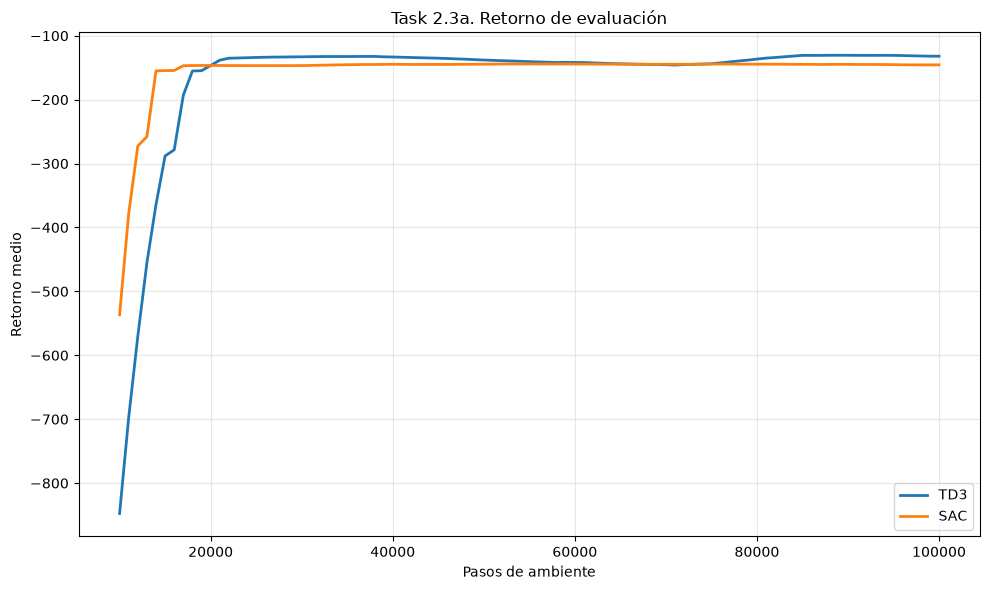

Convergencia: primer paso que conserva 95% de la mejora máxima por cinco evaluaciones consecutivas.
TD3: paso=18000, retorno medio en las últimas 10 evaluaciones=-132.05
SAC: paso=14000, retorno medio en las últimas 10 evaluaciones=-145.54
Con este criterio, SAC converge antes por 4000 pasos.
Mayor retorno final promedio: TD3.
Task 1.1b anticipaba que la exploración estocástica de SAC puede ayudar en simulación; esa expectativa no garantiza que SAC converja antes en este entorno.
El retorno final favorece a TD3, así que el resultado no coincide con la expectativa de mayor retorno para SAC. Pendulum es un proxy de baja dimensión; ruido de exploración, temperatura entrópica, hiperparámetros y una sola semilla pueden cambiar el orden.


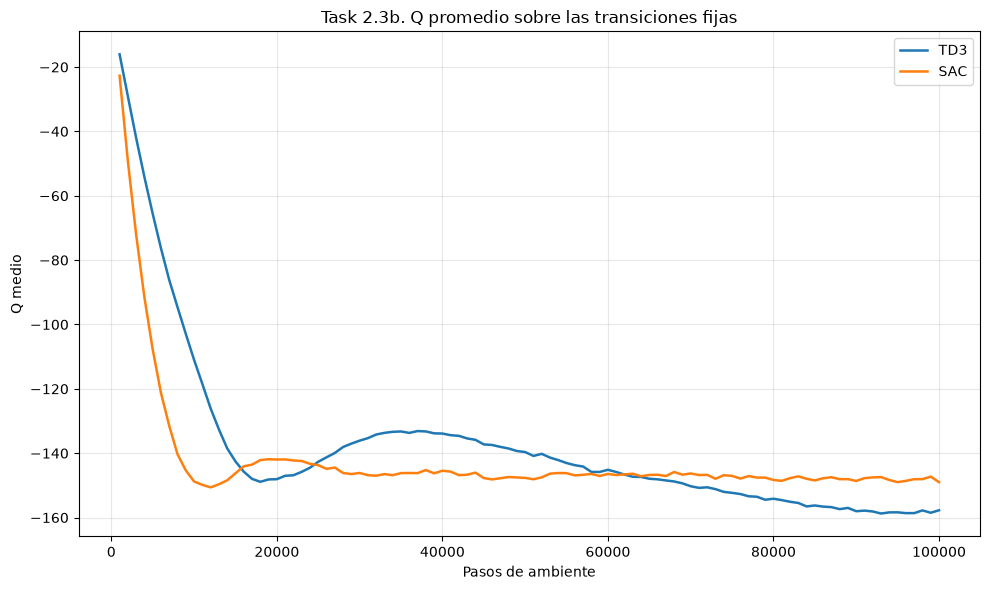

Q final TD3=-157.728; SAC=-148.988.
Ambas curvas se evalúan sobre el mismo conjunto fijo de 1,000 transiciones.
SAC estima Q más alto al final. Parte de la diferencia puede venir de su objetivo soft, que suma entropía al retorno; no basta para concluir que sobreestima.
Como en Task 1.2b, el mínimo de dos críticos y el suavizado del target hacen a TD3 conservador; SAC también toma el mínimo, pero suma el término de entropía. Sus magnitudes no son directamente equivalentes porque los objetivos de valor difieren.


In [7]:
try:
    import matplotlib.pyplot as plt
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError("Task 2.3 requiere matplotlib.") from exc


def trailing_mean(values, window=10):
    values = np.asarray(values, dtype=np.float64)
    if len(values) < window:
        raise ValueError(f"Se necesitan al menos {window} evaluaciones para calcular la media móvil.")
    return np.convolve(values, np.ones(window, dtype=np.float64) / window, mode="valid")


def convergence_step(steps, smoothed_values, fraction=0.95, sustain=5):
    """Primer paso que mantiene al menos el 95% de la mejora observada durante cinco evaluaciones."""
    steps = np.asarray(steps)
    values = np.asarray(smoothed_values)
    if len(values) < sustain:
        return None
    low, high = float(values.min()), float(values.max())
    if np.isclose(low, high):
        return int(steps[0])
    threshold = low + fraction * (high - low)
    for i in range(len(values) - sustain + 1):
        if np.all(values[i:i + sustain] >= threshold):
            return int(steps[i])
    return None


required = ("td3_result", "sac_result")
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(
        "Faltan resultados de Task 2.1. Ejecuta sus dos entrenamientos en este kernel "
        "antes de generar las gráficas."
    )

td3_metrics = td3_result["metrics"]
sac_metrics = sac_result["metrics"]
if not td3_metrics or not sac_metrics:
    raise RuntimeError("Las métricas están vacías. Revisa que TD3 y SAC hayan completado el entrenamiento.")

td3_steps = np.asarray([row["step"] for row in td3_metrics])
sac_steps = np.asarray([row["step"] for row in sac_metrics])
td3_returns = np.asarray([row["eval_return"] for row in td3_metrics])
sac_returns = np.asarray([row["eval_return"] for row in sac_metrics])
td3_q = np.asarray([row["q_mean"] for row in td3_metrics])
sac_q = np.asarray([row["q_mean"] for row in sac_metrics])

td3_return_smooth = trailing_mean(td3_returns, window=10)
sac_return_smooth = trailing_mean(sac_returns, window=10)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(td3_steps[9:], td3_return_smooth, label="TD3", linewidth=2)
ax.plot(sac_steps[9:], sac_return_smooth, label="SAC", linewidth=2)
ax.set(title="Task 2.3a. Retorno de evaluación", xlabel="Pasos de ambiente", ylabel="Retorno medio")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

td3_conv = convergence_step(td3_steps[9:], td3_return_smooth)
sac_conv = convergence_step(sac_steps[9:], sac_return_smooth)
td3_final = float(np.mean(td3_returns[-10:]))
sac_final = float(np.mean(sac_returns[-10:]))
print("Convergencia: primer paso que conserva 95% de la mejora máxima por cinco evaluaciones consecutivas.")
print(f"TD3: paso={td3_conv if td3_conv is not None else 'no alcanzado'}, retorno medio en las últimas 10 evaluaciones={td3_final:.2f}")
print(f"SAC: paso={sac_conv if sac_conv is not None else 'no alcanzado'}, retorno medio en las últimas 10 evaluaciones={sac_final:.2f}")
if td3_conv is None and sac_conv is None:
    print("Con este criterio, ninguno de los dos muestra convergencia sostenida dentro del entrenamiento.")
elif td3_conv is None:
    print("Con este criterio, SAC converge antes; TD3 no alcanza el umbral sostenido.")
elif sac_conv is None:
    print("Con este criterio, TD3 converge antes; SAC no alcanza el umbral sostenido.")
elif td3_conv < sac_conv:
    print(f"Con este criterio, TD3 converge antes por {sac_conv - td3_conv} pasos.")
elif sac_conv < td3_conv:
    print(f"Con este criterio, SAC converge antes por {td3_conv - sac_conv} pasos.")
else:
    print("Con este criterio, TD3 y SAC alcanzan el umbral al mismo paso.")

higher_final = "TD3" if td3_final > sac_final else "SAC" if sac_final > td3_final else "empate"
print(f"Mayor retorno final promedio: {higher_final}.")
print(
    "Task 1.1b anticipaba que la exploración estocástica de SAC puede ayudar en simulación; "
    "esa expectativa no garantiza que SAC converja antes en este entorno."
)
if sac_final > td3_final:
    print("El retorno final favorece a SAC y concuerda con esa parte de la predicción.")
elif td3_final > sac_final:
    print(
        "El retorno final favorece a TD3, así que el resultado no coincide con la expectativa "
        "de mayor retorno para SAC. Pendulum es un proxy de baja dimensión; ruido de exploración, "
        "temperatura entrópica, hiperparámetros y una sola semilla pueden cambiar el orden."
    )
else:
    print("Los retornos finales empatan; esta ejecución no distingue una ventaja entre ambos.")

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(td3_steps, td3_q, label="TD3", linewidth=1.8)
ax.plot(sac_steps, sac_q, label="SAC", linewidth=1.8)
ax.set(title="Task 2.3b. Q promedio sobre las transiciones fijas", xlabel="Pasos de ambiente", ylabel="Q medio")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print(f"Q final TD3={td3_q[-1]:.3f}; SAC={sac_q[-1]:.3f}.")
print("Ambas curvas se evalúan sobre el mismo conjunto fijo de 1,000 transiciones.")
q_gap = float(sac_q[-1] - td3_q[-1])
if q_gap > 0:
    print(
        "SAC estima Q más alto al final. Parte de la diferencia puede venir de su objetivo soft, "
        "que suma entropía al retorno; no basta para concluir que sobreestima."
    )
elif q_gap < 0:
    print(
        "TD3 estima Q más alto al final. Suavizado del target y el mínimo de los twin critics "
        "pueden moderar Q; SAC también usa el mínimo, pero su objetivo incluye entropía."
    )
else:
    print("Los Q finales coinciden. En cualquier caso, SAC estima retorno soft y TD3 retorno extrínseco.")
print(
    "Como en Task 1.2b, el mínimo de dos críticos y el suavizado del target hacen a TD3 conservador; "
    "SAC también toma el mínimo, pero suma el término de entropía. Sus magnitudes no son "
    "directamente equivalentes porque los objetivos de valor difieren."
)


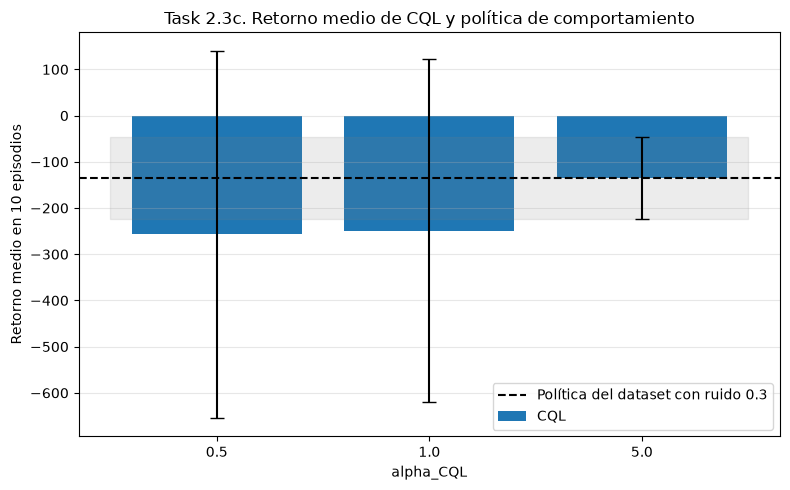

Política del dataset: retorno=-134.44 ± 88.60
alpha_CQL=0.5: retorno CQL=-257.11 ± 397.56; diferencia vs. comportamiento=-122.67
alpha_CQL=1: retorno CQL=-249.27 ± 371.50; diferencia vs. comportamiento=-114.83
alpha_CQL=5: retorno CQL=-134.22 ± 88.61; diferencia vs. comportamiento=0.22
Mejor valor probado: alpha_CQL=5, retorno=-134.22.
Lectura posible: la penalización más alta redujo mejor la sobreestimación de acciones poco cubiertas. Valida que no haya sacrificado retorno o seguridad en otros episodios y semillas.
Al menos una política CQL supera el promedio de la política que generó el dataset. El mejor alpha es el de mayor retorno medio en esta evaluación.

Task 2.3d. Lectura para el control de turbinas
En Pendulum-v1, el mayor retorno final entre TD3 y SAC fue TD3 (-132.05); el mejor CQL fue alpha_CQL=5 (-134.22) frente a -134.44 para el comportamiento.
Si existe un simulador fiable y barato, conviene entrenar en él con el algoritmo online que haya rendido mejor aquí: TD3 si se pr

In [8]:
needed = ("cql_results", "comparison", "behavior_return", "behavior_episode_returns")
missing = [name for name in needed if name not in globals()]
if missing:
    raise RuntimeError(
        "Faltan resultados de Task 2.2. Ejecuta el entrenamiento offline y la evaluación "
        "de los tres valores de alpha_CQL en este kernel."
    )

if not comparison:
    raise RuntimeError("La lista comparison está vacía; no hay retornos de evaluación para comparar.")

cql_alphas = [row["alpha_cql"] for row in comparison]
cql_means = np.asarray([row["cql_mean_return"] for row in comparison], dtype=np.float64)
cql_stds = np.asarray([
    np.std(row["cql_episode_returns"], ddof=1) if len(row["cql_episode_returns"]) > 1 else 0.0
    for row in comparison
])
behavior_std = float(np.std(behavior_episode_returns, ddof=1)) if len(behavior_episode_returns) > 1 else 0.0
best_index = int(np.argmax(cql_means))
best_alpha = cql_alphas[best_index]
best_cql_return = float(cql_means[best_index])
cql_beats_behavior = best_cql_return > float(behavior_return)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
    [str(alpha) for alpha in cql_alphas],
    cql_means,
    yerr=cql_stds,
    capsize=5,
    label="CQL",
)
ax.axhline(
    float(behavior_return),
    color="black",
    linestyle="--",
    label="Política del dataset con ruido 0.3",
)
ax.fill_between(
    [-0.5, len(cql_alphas) - 0.5],
    [behavior_return - behavior_std, behavior_return - behavior_std],
    [behavior_return + behavior_std, behavior_return + behavior_std],
    color="gray",
    alpha=0.15,
)
ax.set(title="Task 2.3c. Retorno medio de CQL y política de comportamiento", xlabel="alpha_CQL", ylabel="Retorno medio en 10 episodios")
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print(f"Política del dataset: retorno={behavior_return:.2f} ± {behavior_std:.2f}")
for row, std in zip(comparison, cql_stds):
    print(
        f"alpha_CQL={row['alpha_cql']:g}: retorno CQL="
        f"{row['cql_mean_return']:.2f} ± {std:.2f}; "
        f"diferencia vs. comportamiento={row['difference']:.2f}"
    )
print(f"Mejor valor probado: alpha_CQL={best_alpha:g}, retorno={best_cql_return:.2f}.")
if np.isclose(best_alpha, 0.5):
    print(
        "Lectura posible: la penalización más baja permitió aprovechar mejor las acciones del "
        "dataset; los valores mayores pudieron restringir demasiado la mejora. Confirma esta "
        "hipótesis con más semillas y métricas de seguridad."
    )
elif np.isclose(best_alpha, 1.0):
    print(
        "Lectura posible: alpha_CQL=1 equilibró la reducción de Q fuera del soporte con el "
        "aprovechamiento de las acciones observadas. La diferencia no demuestra causalidad con "
        "una sola semilla."
    )
elif np.isclose(best_alpha, 5.0):
    print(
        "Lectura posible: la penalización más alta redujo mejor la sobreestimación de acciones "
        "poco cubiertas. Valida que no haya sacrificado retorno o seguridad en otros episodios y semillas."
    )
if cql_beats_behavior:
    print(
        "Al menos una política CQL supera el promedio de la política que generó el dataset. "
        "El mejor alpha es el de mayor retorno medio en esta evaluación."
    )
else:
    print(
        "Ninguna política CQL supera el promedio de la política que generó el dataset. "
        "El buffer contiene 50,000 transiciones de un solo TD3 entrenado 20,000 pasos, "
        "con ruido gaussiano de 0.3; por eso su cobertura sigue concentrada alrededor de "
        "una política subóptima. CQL no puede recuperar acciones seguras y mejores que no "
        "aparecen en esos datos, y una penalización conservadora alta también puede frenar "
        "la mejora fuera de las acciones observadas."
    )

online_returns = {"TD3": td3_final, "SAC": sac_final}
best_online_name = max(online_returns, key=online_returns.get)
best_online_return = online_returns[best_online_name]
print()
print("Task 2.3d. Lectura para el control de turbinas")
print(
    f"En Pendulum-v1, el mayor retorno final entre TD3 y SAC fue {best_online_name} "
    f"({best_online_return:.2f}); el mejor CQL fue alpha_CQL={best_alpha:g} "
    f"({best_cql_return:.2f}) frente a {behavior_return:.2f} para el comportamiento."
)
print(
    "Si existe un simulador fiable y barato, conviene entrenar en él con el algoritmo online "
    "que haya rendido mejor aquí: TD3 si se prioriza control determinista, SAC si sus curvas "
    "muestran una mejora más rápida o un retorno final mayor. La ventaja depende de las "
    "curvas medidas, no solo de la expectativa teórica."
)
if cql_beats_behavior:
    print(
        "Si las interacciones reales son caras o riesgosas y los registros históricos cubren "
        "los estados y acciones de operación, CQL es una opción concreta: en este proxy superó "
        "a la política que produjo sus datos. Antes del despliegue aún se deben verificar límites "
        "y estabilidad en un entorno representativo."
    )
else:
    print(
        "En este experimento CQL no mejoró al comportamiento, así que no hay evidencia para "
        "desplegarlo solo por evitar interacción. Si no hay simulador fiable, primero ampliaría "
        "los registros con operación segura y diversa."
    )
if cql_beats_behavior:
    print(
        "Si el despliegue urge, CQL puede pasar a una evaluación en sombra o con límites "
        "estrictos, siempre que las pruebas de seguridad también sean satisfactorias. Este "
        "resultado de Pendulum por sí solo no valida el control de una turbina."
    )
else:
    print(
        "Si el despliegue urge, conservaría el controlador seguro actual. Este experimento "
        "no respalda cambiarlo por CQL, y el entrenamiento online debe ocurrir primero en un "
        "simulador fiable."
    )
print(
    "La cautela principal es la calidad del dataset: el buffer del ejercicio es sintético y viene "
    "de una sola política TD3 con ruido, no de operadores humanos heterogéneos. El resultado de "
    "CQL en ese buffer no predice por sí solo el rendimiento con registros reales de turbinas."
)


### 2.3e. Paper de Offline RL aplicado a control energético

Zhan et al. (ICLR 2025) estudian el control de las unidades de enfriamiento de centros de datos. El objetivo es bajar el consumo de los equipos sin rebasar los límites de temperatura. Los autores señalan dos problemas que también aparecen en Offline RL: construir un simulador fiable es difícil y los registros históricos cubren una fracción limitada de las acciones posibles. Sus datos vienen de controladores convencionales, así que la política aprende sobre una distribución de acciones estrecha.

El método primero aprende un modelo térmico con una red neuronal de grafos que representa la relación entre unidades y sensores, y regulariza sus dinámicas latentes con simetría temporal. Después aprende la política offline en ese espacio latente, con una optimización cercana a TD3+BC: el actor busca acciones de alto valor, se mantiene cerca de las acciones del dataset y añade una penalización de consistencia física. Esa regularización aborda el riesgo de extrapolar fuera del soporte observado.

El estudio usa registros de dos salas comerciales, con cerca de 180,000 muestras durante 20 meses en una y 140,000 durante 15 meses en la otra. En pruebas de producción que sumaron 2,000 horas, reporta ahorros de energía de 14% a 21% sin violar las restricciones operativas. En el testbed comparan además contra métodos como CQL; algunas políticas basales reducen más el consumo, pero incumplen la seguridad térmica. La limitación de cobertura sí está presente. El trabajo la mitiga con estructura física, regularización y una función de recompensa sensible a seguridad. En nuestro ejercicio, el dataset es más limitado en origen: 50,000 transiciones de una sola política TD3 con ruido, no registros de varios operadores. Por eso un resultado de CQL aquí no permite concluir cómo rendiría con registros reales más diversos.

Referencia: [Zhan et al., “Data Center Cooling System Optimization Using Offline Reinforcement Learning”, ICLR 2025](https://proceedings.iclr.cc/paper_files/paper/2025/hash/76d2f8e328e1081c22a77ca0fa330ca5-Abstract-Conference.html), [paper completo](https://proceedings.iclr.cc/paper_files/paper/2025/file/76d2f8e328e1081c22a77ca0fa330ca5-Paper-Conference.pdf).
